In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

for root, dirs, files in os.walk(ROOT):
    for file in files:
        if file.endswith(".geojson"):
            print(os.path.join(root, file))

/content/drive/MyDrive/RoofMaterialProject/borde_rural/test-borde_rural.geojson
/content/drive/MyDrive/RoofMaterialProject/borde_rural/train-borde_rural.geojson
/content/drive/MyDrive/RoofMaterialProject/borde_soacha/test-borde_soacha.geojson
/content/drive/MyDrive/RoofMaterialProject/borde_soacha/train-borde_soacha.geojson


In [4]:
import geopandas as gpd
import pandas as pd
import os

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

FILES = {
    "rural_train": f"{ROOT}/borde_rural/train-borde_rural.geojson",
    "rural_test": f"{ROOT}/borde_rural/test-borde_rural.geojson",
    "soacha_train": f"{ROOT}/borde_soacha/train-borde_soacha.geojson",
    "soacha_test": f"{ROOT}/borde_soacha/test-borde_soacha.geojson"
}

# Load all four GeoJSON files
gdfs = {}

for name, path in FILES.items():
    gdfs[name] = gpd.read_file(path)

    print(f"\n{name.upper()}")
    print("Buildings:", len(gdfs[name]))
    print("CRS:", gdfs[name].crs)
    print("Columns:", gdfs[name].columns.tolist())
    print("Geometry types:", gdfs[name].geometry.geom_type.value_counts().to_dict())
    print("Invalid geometries:", (~gdfs[name].geometry.is_valid).sum())

print("\nAll four files loaded successfully.")


RURAL_TRAIN
Buildings: 4361
CRS: EPSG:4326
Columns: ['id', 'roof_material', 'verified', 'geometry']
Geometry types: {'Polygon': 4353, 'MultiPolygon': 8}
Invalid geometries: 0

RURAL_TEST
Buildings: 2160
CRS: EPSG:4326
Columns: ['id', 'geometry']
Geometry types: {'Polygon': 2157, 'MultiPolygon': 3}
Invalid geometries: 0

SOACHA_TRAIN
Buildings: 5995
CRS: EPSG:4326
Columns: ['id', 'roof_material', 'verified', 'geometry']
Geometry types: {'Polygon': 5987, 'MultiPolygon': 8}
Invalid geometries: 0

SOACHA_TEST
Buildings: 3017
CRS: EPSG:4326
Columns: ['id', 'geometry']
Geometry types: {'Polygon': 3013, 'MultiPolygon': 4}
Invalid geometries: 0

All four files loaded successfully.


In [5]:

import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import box

# Grid configuration
GRID_SIZE = 100  # metres
TARGET_CRS = "EPSG:32618"

regions = {
    "borde_rural": gdfs["rural_test"],
    "borde_soacha": gdfs["soacha_test"]
}

grid_results = {}
building_assignments = {}

for region_name, buildings in regions.items():

    print(f"\nProcessing: {region_name}")

    # Project building geometries into metres
    projected = buildings.to_crs(TARGET_CRS).copy()

    # Calculate a representative point inside each building
    points = projected.geometry.representative_point()

    # Extract point coordinates
    x = points.x
    y = points.y

    # Align grid origin to multiples of 100 metres
    origin_x = np.floor(projected.total_bounds[0] / GRID_SIZE) * GRID_SIZE
    origin_y = np.floor(projected.total_bounds[1] / GRID_SIZE) * GRID_SIZE

    # Calculate grid column and row
    cols = np.floor((x - origin_x) / GRID_SIZE).astype(int)
    rows = np.floor((y - origin_y) / GRID_SIZE).astype(int)

    # Store building-to-grid assignment
    assignments = pd.DataFrame({
        "building_id": projected["id"].values,
        "grid_row": rows.values,
        "grid_col": cols.values
    })

    assignments["grid_id"] = (
        region_name + "_" +
        assignments["grid_row"].astype(str) + "_" +
        assignments["grid_col"].astype(str)
    )

    # Count buildings in each occupied grid cell
    counts = (
        assignments.groupby(["grid_row", "grid_col"])
        .size()
        .reset_index(name="building_count")
    )

    # Generate grid polygons
    counts["geometry"] = counts.apply(
        lambda r: box(
            origin_x + r["grid_col"] * GRID_SIZE,
            origin_y + r["grid_row"] * GRID_SIZE,
            origin_x + (r["grid_col"] + 1) * GRID_SIZE,
            origin_y + (r["grid_row"] + 1) * GRID_SIZE
        ),
        axis=1
    )

    grid = gpd.GeoDataFrame(
        counts,
        geometry="geometry",
        crs=TARGET_CRS
    )

    grid["grid_id"] = (
        region_name + "_" +
        grid["grid_row"].astype(str) + "_" +
        grid["grid_col"].astype(str)
    )

    # Save results in memory
    grid_results[region_name] = grid
    building_assignments[region_name] = assignments

    print("Test buildings:", len(projected))
    print("Occupied grid cells:", len(grid))
    print("Assigned buildings:", len(assignments))
    print("Unassigned buildings:", len(projected) - len(assignments))
    print("Minimum buildings per occupied cell:", grid["building_count"].min())
    print("Maximum buildings per occupied cell:", grid["building_count"].max())
    print("Average buildings per occupied cell:", round(grid["building_count"].mean(), 2))

print("\nGrid generation completed.")



Processing: borde_rural
Test buildings: 2160
Occupied grid cells: 111
Assigned buildings: 2160
Unassigned buildings: 0
Minimum buildings per occupied cell: 1
Maximum buildings per occupied cell: 43
Average buildings per occupied cell: 19.46

Processing: borde_soacha
Test buildings: 3017
Occupied grid cells: 147
Assigned buildings: 3017
Unassigned buildings: 0
Minimum buildings per occupied cell: 1
Maximum buildings per occupied cell: 48
Average buildings per occupied cell: 20.52

Grid generation completed.


In [6]:
import os

OUTPUT_DIR = f"{ROOT}/vulnerability_mapping/grids"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for region, grid in grid_results.items():

    # Save grid polygons
    grid.to_file(
        f"{OUTPUT_DIR}/{region}_100m_grid.geojson",
        driver="GeoJSON"
    )

    # Save building-to-grid assignments
    building_assignments[region].to_csv(
        f"{OUTPUT_DIR}/{region}_building_grid_assignments.csv",
        index=False
    )

    print(f"Saved: {region}")

print("\nAll grid files saved successfully!")
print("Location:", OUTPUT_DIR)

Saved: borde_rural
Saved: borde_soacha

All grid files saved successfully!
Location: /content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/grids


In [7]:
"""geting predictions of test dataset 5177 records"""

'geting predictions of test dataset 5177 records'

In [10]:
import os

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

paths = [
    f"{ROOT}/patches/test/test_patch_manifest.csv",
    f"{ROOT}/features/svm_custom_4class_final.joblib",
    f"{ROOT}/src/feature_extractor.py"
]

for path in paths:
    print(
        "EXISTS" if os.path.exists(path) else "MISSING",
        path
    )

EXISTS /content/drive/MyDrive/RoofMaterialProject/patches/test/test_patch_manifest.csv
EXISTS /content/drive/MyDrive/RoofMaterialProject/features/svm_custom_4class_final.joblib
MISSING /content/drive/MyDrive/RoofMaterialProject/src/feature_extractor.py


In [11]:
import os

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

print("Searching for feature extraction files...\n")

for current_root, dirs, files in os.walk(ROOT):
    for file in files:
        if "feature" in file.lower() or file == "predict.py":
            print(os.path.join(current_root, file))

Searching for feature extraction files...

/content/drive/MyDrive/RoofMaterialProject/features/roof_features.csv
/content/drive/MyDrive/RoofMaterialProject/features/roof_features_44.csv
/content/drive/MyDrive/RoofMaterialProject/features/roof_features_44_with_labels.csv
/content/drive/MyDrive/RoofMaterialProject/features/roof_features_4class.csv
/content/drive/MyDrive/RoofMaterialProject/features/feature_extractor.py
/content/drive/MyDrive/RoofMaterialProject/features/__pycache__/feature_extractor.cpython-313.pyc
/content/drive/MyDrive/RoofMaterialProject/RoofRiskAI/src/feature_extractor.py
/content/drive/MyDrive/RoofMaterialProject/RoofRiskAI/src/predict.py
/content/drive/MyDrive/RoofMaterialProject/RoofRiskAI/src/__pycache__/feature_extractor.cpython-313.pyc


In [12]:
import pandas as pd

manifest_path = f"{ROOT}/patches/test/test_patch_manifest.csv"

manifest = pd.read_csv(manifest_path)

print("Shape:", manifest.shape)
print("\nColumns:")
print(manifest.columns.tolist())

print("\nFirst 5 records:")
display(manifest.head())

Shape: (5177, 5)

Columns:
['region', 'building_id', 'patch_path', 'status', 'error']

First 5 records:


,region,building_id,patch_path,status,error
0,borde_rural,7a4d630a,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN
1,borde_rural,7a4bbbd6,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN
2,borde_rural,7a4ac744,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN
3,borde_rural,7a4881fa,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN
4,borde_rural,7a4aa4a8,/content/drive/MyDrive/RoofMaterialProject/pat...,success,NaN


In [13]:
print("Total records:", len(manifest))

print("\nStatus distribution:")
print(manifest["status"].value_counts(dropna=False))

print("\nRegion distribution:")
print(manifest["region"].value_counts())

print("\nMissing patch paths:", manifest["patch_path"].isna().sum())

print("\nExisting patch files:",
      manifest["patch_path"].apply(os.path.exists).sum())

print("\nMissing patch files:",
      (~manifest["patch_path"].apply(os.path.exists)).sum())

Total records: 5177

Status distribution:
status
success    5177
Name: count, dtype: int64

Region distribution:
region
borde_soacha    3017
borde_rural     2160
Name: count, dtype: int64

Missing patch paths: 0

Existing patch files: 5177

Missing patch files: 0


In [14]:
from pathlib import Path

extractors = [
    Path(f"{ROOT}/features/feature_extractor.py"),
    Path(f"{ROOT}/RoofRiskAI/src/feature_extractor.py"),
    Path(f"{ROOT}/RoofRiskAI/src/predict.py")
]

for file in extractors:
    print("\n" + "="*70)
    print("FILE:", file)
    print("="*70)

    with open(file, "r", encoding="utf-8") as f:
        print(f.read())


FILE: /content/drive/MyDrive/RoofMaterialProject/features/feature_extractor.py

import numpy as np
import pandas as pd
from PIL import Image

from skimage.color import rgb2gray
from skimage.feature import (
    local_binary_pattern,
    graycomatrix,
    graycoprops
)

FEATURE_COLS = [
    'r_mean', 'r_std', 'r_p10', 'r_p90',
    'g_mean', 'g_std', 'g_p10', 'g_p90',
    'b_mean', 'b_std', 'b_p10', 'b_p90',
    'h_mean', 'h_std', 's_mean', 's_std',
    'v_mean', 'v_std',
    'lbp_bin_0', 'lbp_bin_1', 'lbp_bin_2',
    'lbp_bin_3', 'lbp_bin_4', 'lbp_bin_5',
    'lbp_bin_6', 'lbp_bin_7', 'lbp_bin_8', 'lbp_bin_9',
    'glcm_contrast_d1_mean', 'glcm_contrast_d1_std',
    'glcm_contrast_d2_mean', 'glcm_contrast_d2_std',
    'glcm_homogeneity_d1_mean', 'glcm_homogeneity_d1_std',
    'glcm_homogeneity_d2_mean', 'glcm_homogeneity_d2_std',
    'glcm_energy_d1_mean', 'glcm_energy_d1_std',
    'glcm_energy_d2_mean', 'glcm_energy_d2_std',
    'glcm_correlation_d1_mean', 'glcm_correlation_d1_std',
 

In [16]:

import os
import sys
import joblib
import pandas as pd

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

# Load the original feature extractor
FEATURE_DIR = f"{ROOT}/features"

if FEATURE_DIR not in sys.path:
    sys.path.insert(0, FEATURE_DIR)

from feature_extractor import extract_features, FEATURE_COLS

# Load the final trained SVM
MODEL_PATH = f"{ROOT}/features/svm_custom_4class_final.joblib"
model = joblib.load(MODEL_PATH)

# Verify expected feature names and order
expected_features = list(
    model.named_steps["scaler"].feature_names_in_
)

print("Model loaded successfully")
print("Expected model features:", len(expected_features))
print("Extractor features:", len(FEATURE_COLS))
print("Feature order matches:", expected_features == FEATURE_COLS)
print("Model classes:", model.classes_)

assert expected_features == FEATURE_COLS, \
    "Feature names or order do not match!"

# Extract features from one test patch
sample_path = manifest.iloc[0]["patch_path"]

sample_features = extract_features(sample_path)

print("\nExtracted feature shape:", sample_features.shape)
print("Sample patch:", sample_path)

assert sample_features.shape == (1, 44)

# Predict one sample
sample_prediction = model.predict(sample_features)[0]

print("\nSample predicted roof material:", sample_prediction)
print("\nSingle-patch inference successful!")


Model loaded successfully
Expected model features: 44
Extractor features: 44
Feature order matches: True
Model classes: ['concrete_cement' 'healthy_metal' 'incomplete' 'irregular_metal']

Extracted feature shape: (1, 44)
Sample patch: /content/drive/MyDrive/RoofMaterialProject/patches/test/borde_rural/7a4d630a.jpg

Sample predicted roof material: healthy_metal

Single-patch inference successful!


In [18]:

import os
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

# Output directory
OUTPUT_DIR = f"{ROOT}/vulnerability_mapping/inference"
os.makedirs(OUTPUT_DIR, exist_ok=True)

feature_records = []
prediction_records = []
failed_records = []

# Process all test patches
for row in tqdm(
    manifest.itertuples(index=False),
    total=len(manifest),
    desc="Predicting test buildings"
):
    try:
        # Extract exactly the 44 features
        features = extract_features(row.patch_path)

        features = features.reindex(columns=FEATURE_COLS)

        # Predict roof material
        prediction = model.predict(features)[0]

        # Preserve metadata
        metadata = {
            "building_id": row.building_id,
            "region": row.region
        }

        # Store feature record
        feature_records.append({
            **metadata,
            **features.iloc[0].to_dict()
        })

        # Store prediction record
        prediction_records.append({
            **metadata,
            "predicted": prediction
        })

    except Exception as e:
        failed_records.append({
            "building_id": row.building_id,
            "region": row.region,
            "error": str(e)
        })

# Convert to DataFrames
test_features = pd.DataFrame(feature_records)
test_predictions = pd.DataFrame(prediction_records)
failed_df = pd.DataFrame(failed_records)

# Save outputs
test_features.to_csv(
    f"{OUTPUT_DIR}/test_building_features_44.csv",
    index=False
)

test_predictions.to_csv(
    f"{OUTPUT_DIR}/test_building_predictions.csv",
    index=False
)

failed_df.to_csv(
    f"{OUTPUT_DIR}/test_inference_failures.csv",
    index=False
)

print("\n========== INFERENCE SUMMARY ==========")
print("Expected buildings:", len(manifest))
print("Successful predictions:", len(test_predictions))
print("Failed predictions:", len(failed_df))

print("\nRegion distribution:")
print(test_predictions["region"].value_counts())

print("\nPredicted roof-material distribution:")
print(test_predictions["predicted"].value_counts())

print("\nSaved output directory:", OUTPUT_DIR)


Predicting test buildings:   0%|          | 0/5177 [00:00<?, ?it/s]


========== INFERENCE SUMMARY ==========
Expected buildings: 5177
Successful predictions: 5177
Failed predictions: 0

Region distribution:
region
borde_soacha    3017
borde_rural     2160
Name: count, dtype: int64

Predicted roof-material distribution:
predicted
irregular_metal    2298
healthy_metal      2185
incomplete          379
concrete_cement     315
Name: count, dtype: int64

Saved output directory: /content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/inference


In [19]:

import pandas as pd

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

pred = pd.read_csv(
    f"{ROOT}/vulnerability_mapping/inference/test_building_predictions.csv"
)

print("Shape:", pred.shape)
print("\nColumns:")
print(pred.columns.tolist())

print("\nFirst 5 records:")
display(pred.head())

print("\nMissing values:")
print(pred.isnull().sum())

print("\nPredicted class counts:")
print(pred["predicted"].value_counts() if "predicted" in pred.columns else "Check column names")


Shape: (5177, 3)

Columns:
['building_id', 'region', 'predicted']

First 5 records:


,building_id,region,predicted
0,7a4d630a,borde_rural,healthy_metal
1,7a4bbbd6,borde_rural,irregular_metal
2,7a4ac744,borde_rural,healthy_metal
3,7a4881fa,borde_rural,healthy_metal
4,7a4aa4a8,borde_rural,irregular_metal



Missing values:
building_id    0
region         0
predicted      0
dtype: int64

Predicted class counts:
predicted
irregular_metal    2298
healthy_metal      2185
incomplete          379
concrete_cement     315
Name: count, dtype: int64


In [20]:
"""mapping this test dataset predicts with geojson files"""

'mapping this test dataset predicts with geojson files'

In [21]:

import os
import glob
import geopandas as gpd
import pandas as pd

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

# Locate original test GeoJSON files
rural_files = glob.glob(
    ROOT + "/**/test-borde_rural.geojson", recursive=True
)

soacha_files = glob.glob(
    ROOT + "/**/test-borde_soacha.geojson", recursive=True
)

print("Rural files:", rural_files)
print("Soacha files:", soacha_files)

assert rural_files, "Borde Rural GeoJSON not found"
assert soacha_files, "Borde Soacha GeoJSON not found"

rural = gpd.read_file(rural_files[0])
soacha = gpd.read_file(soacha_files[0])

for name, gdf in [
    ("BORDE RURAL", rural),
    ("BORDE SOACHA", soacha)
]:
    print("\n==========", name, "==========")
    print("Shape:", gdf.shape)
    print("CRS:", gdf.crs)
    print("Columns:", gdf.columns.tolist())

    print("\nFirst 3 records:")
    display(gdf.head(3))

    print("\nGeometry types:")
    print(gdf.geometry.geom_type.value_counts())


Rural files: ['/content/drive/MyDrive/RoofMaterialProject/borde_rural/test-borde_rural.geojson']
Soacha files: ['/content/drive/MyDrive/RoofMaterialProject/borde_soacha/test-borde_soacha.geojson']

========== BORDE RURAL ==========
Shape: (2160, 2)
CRS: EPSG:4326
Columns: ['id', 'geometry']

First 3 records:


,id,geometry
0,7a4d630a,"POLYGON ((-74.159 4.55463, -74.15898 4.5547, -..."
1,7a4bbbd6,"POLYGON ((-74.15955 4.55463, -74.15951 4.55474..."
2,7a4ac744,"POLYGON ((-74.15892 4.55509, -74.15887 4.55507..."



Geometry types:
Polygon         2157
MultiPolygon       3
Name: count, dtype: int64

========== BORDE SOACHA ==========
Shape: (3017, 2)
CRS: EPSG:4326
Columns: ['id', 'geometry']

First 3 records:


,id,geometry
0,7a4adb80,"POLYGON ((-74.17063 4.57266, -74.17062 4.57271..."
1,7a4896cc,"POLYGON ((-74.17087 4.57292, -74.17076 4.5729,..."
2,7a518ee4,"POLYGON ((-74.17076 4.57289, -74.17065 4.57288..."



Geometry types:
Polygon         3013
MultiPolygon       4
Name: count, dtype: int64


In [22]:

import os
import pandas as pd
import geopandas as gpd

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

# Input files
PRED_PATH = (
    f"{ROOT}/vulnerability_mapping/inference/"
    "test_building_predictions.csv"
)

RURAL_PATH = f"{ROOT}/borde_rural/test-borde_rural.geojson"
SOACHA_PATH = f"{ROOT}/borde_soacha/test-borde_soacha.geojson"

# Output directory
OUT = f"{ROOT}/vulnerability_mapping/spatial_join"
os.makedirs(OUT, exist_ok=True)

# Load predictions and original geometries
pred = pd.read_csv(PRED_PATH)
rural = gpd.read_file(RURAL_PATH)
soacha = gpd.read_file(SOACHA_PATH)

# Standardize IDs
pred["building_id"] = pred["building_id"].astype(str).str.strip()
rural["id"] = rural["id"].astype(str).str.strip()
soacha["id"] = soacha["id"].astype(str).str.strip()

# Verify unique identifiers
assert pred["building_id"].is_unique, "Duplicate prediction IDs!"
assert rural["id"].is_unique, "Duplicate Rural IDs!"
assert soacha["id"].is_unique, "Duplicate Soacha IDs!"

# Verify region labels
assert set(pred["region"].unique()) == {
    "borde_rural", "borde_soacha"
}

# Separate predictions by region
rural_pred = pred[pred["region"] == "borde_rural"].copy()
soacha_pred = pred[pred["region"] == "borde_soacha"].copy()

# Check counts
assert len(rural_pred) == len(rural) == 2160
assert len(soacha_pred) == len(soacha) == 3017

# Check exact ID matching
assert set(rural["id"]) == set(rural_pred["building_id"]), \
    "Borde Rural ID mismatch!"

assert set(soacha["id"]) == set(soacha_pred["building_id"]), \
    "Borde Soacha ID mismatch!"

# Join predictions with building geometries
rural_joined = rural.merge(
    rural_pred,
    left_on="id",
    right_on="building_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

soacha_joined = soacha.merge(
    soacha_pred,
    left_on="id",
    right_on="building_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Verify every building was matched
assert (rural_joined["_merge"] == "both").all()
assert (soacha_joined["_merge"] == "both").all()

# Remove temporary merge columns
rural_joined = rural_joined.drop(
    columns=["building_id", "_merge"]
)

soacha_joined = soacha_joined.drop(
    columns=["building_id", "_merge"]
)

# Combine both regions
combined = gpd.GeoDataFrame(
    pd.concat(
        [rural_joined, soacha_joined],
        ignore_index=True
    ),
    geometry="geometry",
    crs="EPSG:4326"
)

# Final validation
assert len(combined) == 5177
assert combined["id"].is_unique
assert combined["predicted"].notna().all()
assert combined.geometry.notna().all()

# Save outputs
combined.to_file(
    f"{OUT}/test_buildings_with_predictions.geojson",
    driver="GeoJSON"
)

# Save attribute-level CSV (without geometry)
combined.drop(columns="geometry").to_csv(
    f"{OUT}/test_buildings_with_predictions.csv",
    index=False
)

# Summary
print("\n========== SPATIAL JOIN SUMMARY ==========")
print("Rural buildings matched:", len(rural_joined))
print("Soacha buildings matched:", len(soacha_joined))
print("Total buildings matched:", len(combined))
print("Unmatched buildings:", 0)
print("Duplicate IDs:", combined["id"].duplicated().sum())
print("Missing predictions:", combined["predicted"].isna().sum())
print("CRS:", combined.crs)

print("\n========== CLASS DISTRIBUTION BY REGION ==========")
display(pd.crosstab(
    combined["region"],
    combined["predicted"],
    margins=True
))

print("\n========== OUTPUT FILES ==========")
print(f"{OUT}/test_buildings_with_predictions.geojson")
print(f"{OUT}/test_buildings_with_predictions.csv")



========== SPATIAL JOIN SUMMARY ==========
Rural buildings matched: 2160
Soacha buildings matched: 3017
Total buildings matched: 5177
Unmatched buildings: 0
Duplicate IDs: 0
Missing predictions: 0
CRS: EPSG:4326

========== CLASS DISTRIBUTION BY REGION ==========


predicted,concrete_cement,healthy_metal,incomplete,irregular_metal,All
region,,,,,
borde_rural,129,1020,135,876,2160
borde_soacha,186,1165,244,1422,3017
All,315,2185,379,2298,5177



========== OUTPUT FILES ==========
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/spatial_join/test_buildings_with_predictions.geojson
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/spatial_join/test_buildings_with_predictions.csv


In [26]:
import geopandas as gpd

ROOT = "/content/drive/MyDrive/RoofMaterialProject"
INPUT_FILE = f"{ROOT}/vulnerability_mapping/spatial_join/test_buildings_with_predictions.geojson"

buildings = gpd.read_file(INPUT_FILE)

print("Columns:", buildings.columns.tolist())
print("\nFirst 5 rows:")
display(buildings.head())

Columns: ['id', 'region', 'predicted', 'geometry']

First 5 rows:


,id,region,predicted,geometry
0,7a4d630a,borde_rural,healthy_metal,"POLYGON ((-74.159 4.55463, -74.15898 4.5547, -..."
1,7a4bbbd6,borde_rural,irregular_metal,"POLYGON ((-74.15955 4.55463, -74.15951 4.55474..."
2,7a4ac744,borde_rural,healthy_metal,"POLYGON ((-74.15892 4.55509, -74.15887 4.55507..."
3,7a4881fa,borde_rural,healthy_metal,"POLYGON ((-74.15887 4.55506, -74.15883 4.55505..."
4,7a4aa4a8,borde_rural,irregular_metal,"POLYGON ((-74.15882 4.55504, -74.15871 4.555, ..."


In [23]:
"""aggregation and calculating building count and roof material percentages"""

'aggregation and calculating building count and roof material percentages'

In [31]:

# STEP 1: HEXAGONAL GRID + BUILDING-LEVEL AGGREGATION

import os
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon

# --------------------------------------------------
# 1. PATHS AND SETTINGS
# --------------------------------------------------

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

INPUT_FILE = (
    f"{ROOT}/vulnerability_mapping/spatial_join/"
    "test_buildings_with_predictions.geojson"
)

OUTPUT_DIR = f"{ROOT}/vulnerability_mapping/grid_aggregation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

HEX_RADIUS = 100  # metres: distance from hexagon centre to vertex
METRIC_CRS = "EPSG:32618"

# --------------------------------------------------
# 2. LOAD BUILDINGS WITH PREDICTIONS
# --------------------------------------------------

buildings = gpd.read_file(INPUT_FILE)

required_columns = ["id", "region", "predicted", "geometry"]
missing = [c for c in required_columns if c not in buildings.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

if buildings.crs is None:
    raise ValueError("Input GeoJSON has no CRS information.")

if buildings["id"].duplicated().any():
    raise ValueError("Duplicate building IDs found.")

if buildings["predicted"].isna().any():
    raise ValueError("Missing roof-material predictions found.")

print("Loaded buildings:", len(buildings))
print("Regions:", buildings["region"].value_counts().to_dict())
print("CRS:", buildings.crs)

# --------------------------------------------------
# 3. PROJECT TO METRES
# --------------------------------------------------

buildings_m = buildings.to_crs(METRIC_CRS).copy()

# Use one representative point per building.
# representative_point() stays inside the polygon.
centres = buildings_m.copy()
centres["geometry"] = centres.geometry.representative_point()

# --------------------------------------------------
# 4. FUNCTION TO CREATE HEXAGONAL GRID
# --------------------------------------------------

def create_hex_grid(gdf, region_name, radius=100):

    minx, miny, maxx, maxy = gdf.total_bounds

    dx = np.sqrt(3) * radius
    dy = 1.5 * radius

    hexagons = []
    grid_ids = []

    row = 0
    y = miny - radius

    while y <= maxy + radius:
        x_offset = (dx / 2) if row % 2 else 0
        x = minx - radius + x_offset
        col = 0

        while x <= maxx + radius:
            # Six vertices, pointy-top hexagon
            angles = np.deg2rad(
                [30, 90, 150, 210, 270, 330]
            )

            coords = [
                (
                    x + radius * np.cos(angle),
                    y + radius * np.sin(angle)
                )
                for angle in angles
            ]

            hexagons.append(Polygon(coords))
            grid_ids.append(f"{region_name}_r{row}_c{col}")

            x += dx
            col += 1

        y += dy
        row += 1

    grid = gpd.GeoDataFrame(
        {"grid_id": grid_ids},
        geometry=hexagons,
        crs=METRIC_CRS
    )

    return grid


# --------------------------------------------------
# 5. ASSIGN BUILDINGS TO HEXAGONS
# --------------------------------------------------

all_grid_results = []

for region_name in sorted(buildings_m["region"].unique()):

    print(f"\nProcessing: {region_name}")

    region_buildings = buildings_m[
        buildings_m["region"] == region_name
    ].copy()

    region_centres = centres[
        centres["region"] == region_name
    ].copy()

    grid = create_hex_grid(
        region_buildings,
        region_name,
        HEX_RADIUS
    )

    # Assign each building representative point to one hexagon
    joined = gpd.sjoin(
        region_centres[
            ["id", "predicted", "geometry"]
        ],
        grid[["grid_id", "geometry"]],
        how="left",
        predicate="within"
    )

    # Check assignment completeness
    unmatched = joined["grid_id"].isna().sum()

    print("Buildings:", len(region_buildings))
    print("Grid cells generated:", len(grid))
    print("Unassigned buildings:", unmatched)

    if unmatched > 0:
        raise ValueError(
            f"{unmatched} buildings were not assigned in {region_name}. "
            "Stop and inspect grid coverage before continuing."
        )

    # Count buildings by grid cell and roof class
    counts = (
        joined.groupby(["grid_id", "predicted"])
        .size()
        .unstack(fill_value=0)
    )

    # Ensure all four expected classes are represented as columns
    expected_classes = [
        "healthy_metal",
        "irregular_metal",
        "incomplete",
        "concrete_cement"
    ]

    for cls in expected_classes:
        if cls not in counts.columns:
            counts[cls] = 0

    counts = counts[expected_classes]

    counts["building_count"] = counts.sum(axis=1)

    # Roof-material percentage per cell
    for cls in expected_classes:
        counts[f"{cls}_pct"] = (
            counts[cls] / counts["building_count"] * 100
        )

    counts = counts.reset_index()

    # Dominant predicted roof material
    counts["dominant_roof_material"] = (
        counts[expected_classes].idxmax(axis=1)
    )

    # Attach statistics to occupied grid cells only
    result = grid.merge(
        counts,
        on="grid_id",
        how="inner",
        validate="one_to_one"
    )

    result["region"] = region_name

    print("Occupied grid cells:", len(result))
    print(
        "Buildings represented:",
        int(result["building_count"].sum())
    )

    all_grid_results.append(result)


# --------------------------------------------------
# 6. COMBINE BOTH REGIONS
# --------------------------------------------------

grid_results = gpd.GeoDataFrame(
    pd.concat(all_grid_results, ignore_index=True),
    geometry="geometry",
    crs=METRIC_CRS
)

# --------------------------------------------------
# 7. VALIDATION
# --------------------------------------------------

total_grid_buildings = int(grid_results["building_count"].sum())

print("\n========== GRID AGGREGATION SUMMARY ==========")
print("Total occupied grid cells:", len(grid_results))
print("Total buildings represented:", total_grid_buildings)
print("Original buildings:", len(buildings_m))

if total_grid_buildings != len(buildings_m):
    raise ValueError("Building count mismatch after aggregation.")

print("\nBuildings per region:")
print(
    grid_results.groupby("region")["building_count"].sum()
)

print("\nRoof-material counts across all grid cells:")
print(
    grid_results[
        ["healthy_metal", "irregular_metal",
         "incomplete", "concrete_cement"]
    ].sum()
)

# --------------------------------------------------
# 8. SAVE OUTPUTS
# --------------------------------------------------

# GeoJSON in geographic coordinates for mapping
grid_geojson = grid_results.to_crs("EPSG:4326")

geojson_path = f"{OUTPUT_DIR}/roof_vulnerability_grid.geojson"
csv_path = f"{OUTPUT_DIR}/roof_vulnerability_grid.csv"

grid_geojson.to_file(
    geojson_path,
    driver="GeoJSON"
)

# CSV without geometry
grid_results.drop(columns="geometry").to_csv(
    csv_path,
    index=False
)

print("\n========== FILES SAVED ==========")
print(geojson_path)
print(csv_path)


Loaded buildings: 5177
Regions: {'borde_soacha': 3017, 'borde_rural': 2160}
CRS: EPSG:4326

Processing: borde_rural
Buildings: 2160
Grid cells generated: 98
Unassigned buildings: 0
Occupied grid cells: 51
Buildings represented: 2160

Processing: borde_soacha
Buildings: 3017
Grid cells generated: 138
Unassigned buildings: 0
Occupied grid cells: 63
Buildings represented: 3017

========== GRID AGGREGATION SUMMARY ==========
Total occupied grid cells: 114
Total buildings represented: 5177
Original buildings: 5177

Buildings per region:
region
borde_rural     2160
borde_soacha    3017
Name: building_count, dtype: int64

Roof-material counts across all grid cells:
healthy_metal      2185
irregular_metal    2298
incomplete          379
concrete_cement     315
dtype: int64

========== FILES SAVED ==========
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/grid_aggregation/roof_vulnerability_grid.geojson
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/grid_aggre

Grid shape: (114, 13)
Columns: ['grid_id', 'healthy_metal', 'irregular_metal', 'incomplete', 'concrete_cement', 'building_count', 'healthy_metal_pct', 'irregular_metal_pct', 'incomplete_pct', 'concrete_cement_pct', 'dominant_roof_material', 'region', 'geometry']


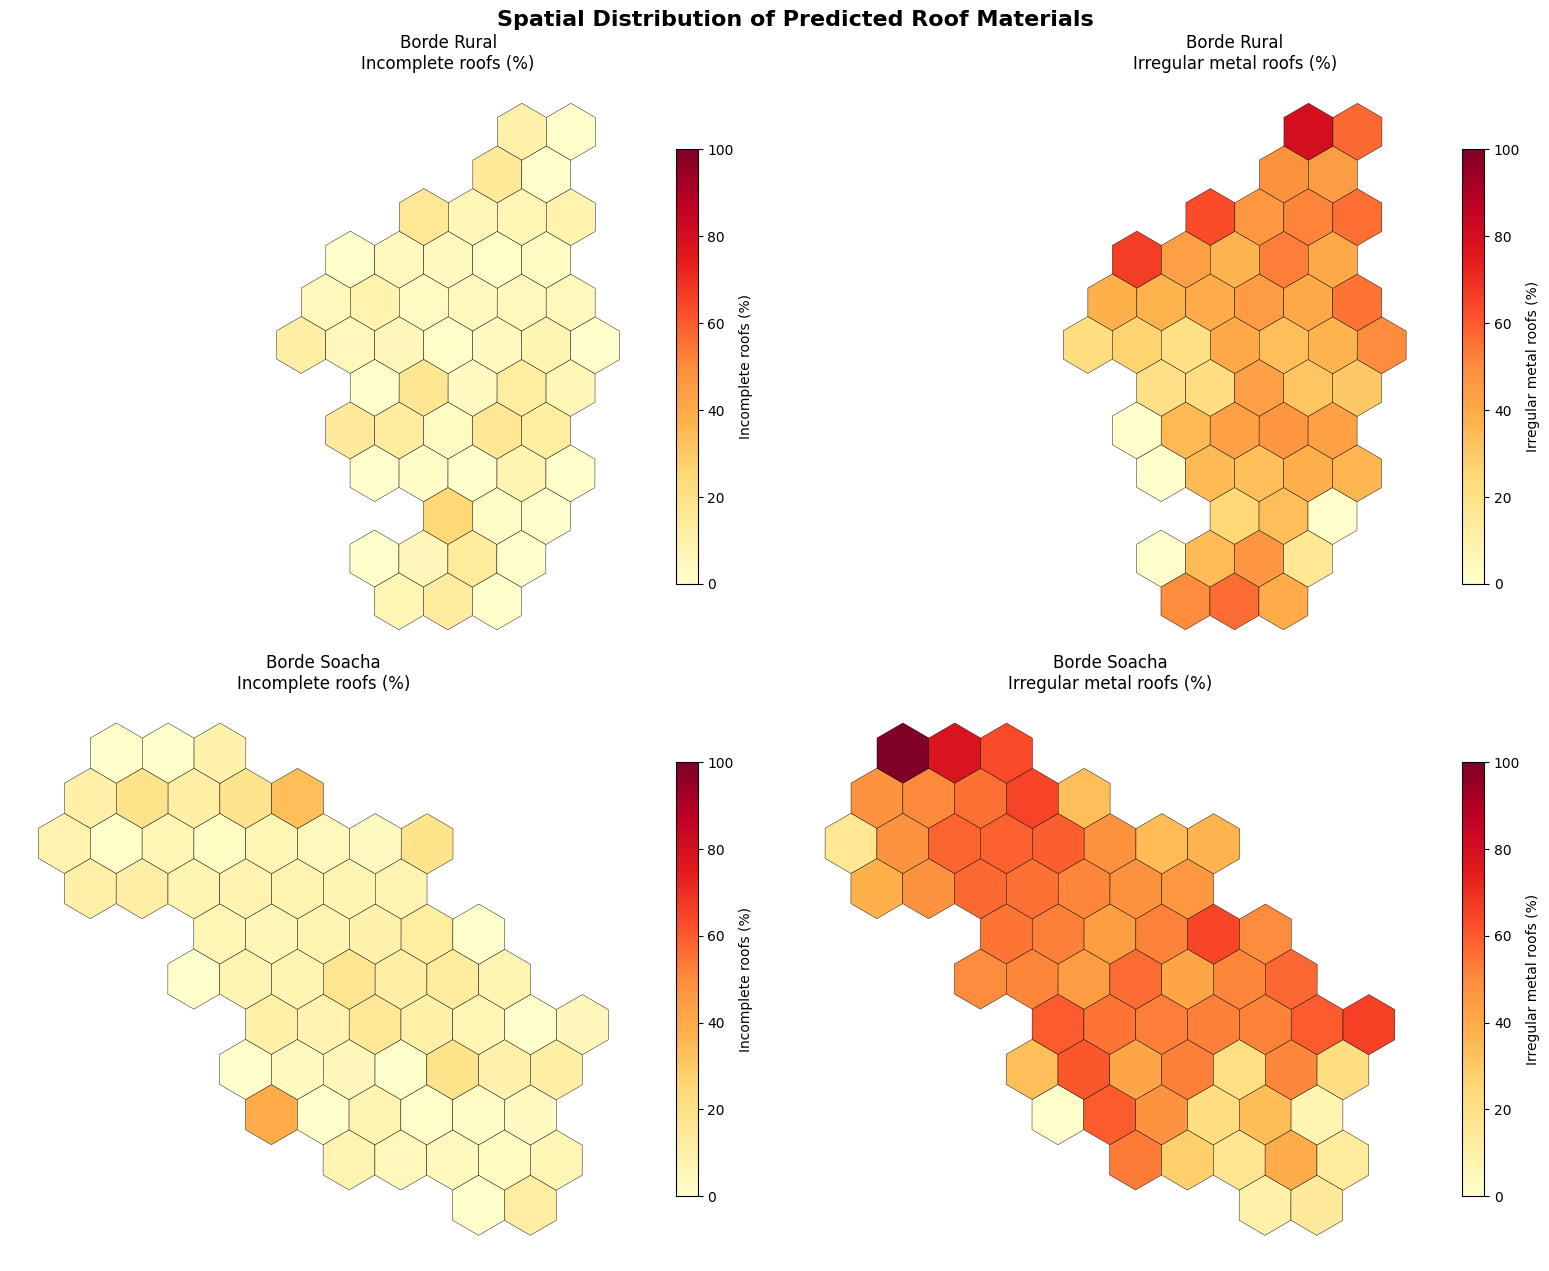

Map saved: /content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/maps/roof_material_spatial_maps.png


In [32]:

import os
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

GRID_FILE = (
    f"{ROOT}/vulnerability_mapping/grid_aggregation/"
    "roof_vulnerability_grid.geojson"
)

OUTPUT_DIR = f"{ROOT}/vulnerability_mapping/maps"
os.makedirs(OUTPUT_DIR, exist_ok=True)

grid = gpd.read_file(GRID_FILE)

print("Grid shape:", grid.shape)
print("Columns:", grid.columns.tolist())

# Plot both regions separately, using consistent colour scales.
fig, axes = plt.subplots(2, 2, figsize=(16, 13))

regions = ["borde_rural", "borde_soacha"]
metrics = [
    ("incomplete_pct", "Incomplete roofs (%)"),
    ("irregular_metal_pct", "Irregular metal roofs (%)")
]

for row, region in enumerate(regions):
    region_data = grid[grid["region"] == region]

    for col, (metric, title) in enumerate(metrics):
        ax = axes[row, col]

        region_data.plot(
            column=metric,
            cmap="YlOrRd",
            linewidth=0.3,
            edgecolor="black",
            legend=True,
            vmin=0,
            vmax=100,
            ax=ax,
            legend_kwds={"label": title, "shrink": 0.75}
        )

        ax.set_title(
            f"{region.replace('_', ' ').title()}\n{title}",
            fontsize=12
        )
        ax.set_axis_off()

plt.suptitle(
    "Spatial Distribution of Predicted Roof Materials",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

map_path = f"{OUTPUT_DIR}/roof_material_spatial_maps.png"
plt.savefig(map_path, dpi=250, bbox_inches="tight")
plt.show()

print("Map saved:", map_path)


In [33]:
"""Calculate building-weighted regional statistics"""

'Calculate building-weighted regional statistics'

In [34]:

import pandas as pd
import geopandas as gpd

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

GRID_FILE = (
    f"{ROOT}/vulnerability_mapping/grid_aggregation/"
    "roof_vulnerability_grid.geojson"
)

grid = gpd.read_file(GRID_FILE)

classes = [
    "healthy_metal",
    "irregular_metal",
    "incomplete",
    "concrete_cement"
]

rows = []

for region, data in grid.groupby("region"):
    total = data["building_count"].sum()

    row = {
        "region": region,
        "occupied_cells": len(data),
        "total_buildings": int(total)
    }

    for cls in classes:
        count = data[cls].sum()
        row[f"{cls}_count"] = int(count)
        row[f"{cls}_pct"] = round(
            count / total * 100, 2
        )

    rows.append(row)

regional_summary = pd.DataFrame(rows)

display(regional_summary)

# Save the regional statistics
OUTPUT_DIR = f"{ROOT}/vulnerability_mapping/grid_aggregation"

regional_summary.to_csv(
    f"{OUTPUT_DIR}/regional_roof_summary.csv",
    index=False
)

print("Regional summary saved successfully.")


,region,occupied_cells,total_buildings,healthy_metal_count,healthy_metal_pct,irregular_metal_count,irregular_metal_pct,incomplete_count,incomplete_pct,concrete_cement_count,concrete_cement_pct
0,borde_rural,51,2160,1020,47.22,876,40.56,135,6.25,129,5.97
1,borde_soacha,63,3017,1165,38.61,1422,47.13,244,8.09,186,6.17


Regional summary saved successfully.


In [35]:
"""roof concern proxy=
RCP = irregular_metal_pct+incomplete_pct"""

'roof concern proxy=\nRCP = irregular_metal_pct+incomplete_pct'

Total occupied cells: 114

Roof Concern Proxy statistics:
count    114.00
mean      49.76
std       18.28
min        0.00
25%       40.00
50%       52.28
75%       61.54
max      100.00
Name: roof_concern_proxy, dtype: float64


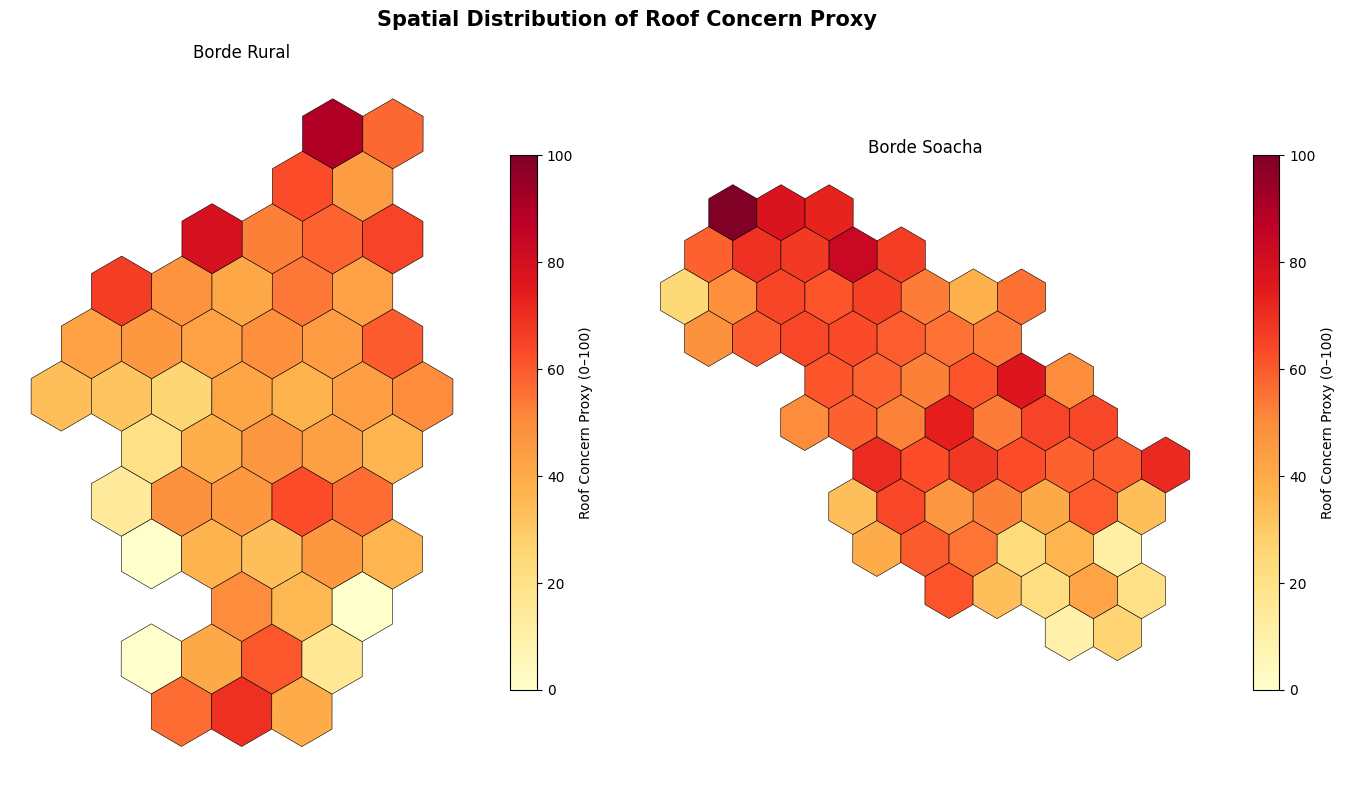


Saved files:
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/roof_concern_analysis/roof_concern_grid.geojson
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/roof_concern_analysis/roof_concern_grid.csv
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/roof_concern_analysis/roof_concern_proxy_map.png


In [36]:

import os
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

INPUT_FILE = (
    f"{ROOT}/vulnerability_mapping/grid_aggregation/"
    "roof_vulnerability_grid.geojson"
)

OUTPUT_DIR = f"{ROOT}/vulnerability_mapping/roof_concern_analysis"
os.makedirs(OUTPUT_DIR, exist_ok=True)

grid = gpd.read_file(INPUT_FILE)

# Keep the two indicators separate
grid["irregular_metal_indicator"] = grid["irregular_metal_pct"]
grid["incomplete_roof_indicator"] = grid["incomplete_pct"]

# Provisional equal-weight roof concern proxy
grid["roof_concern_proxy"] = (
    grid["irregular_metal_indicator"]
    + grid["incomplete_roof_indicator"]
)

# Validate score
assert grid["roof_concern_proxy"].between(0, 100).all()
assert len(grid) == 114

print("Total occupied cells:", len(grid))
print("\nRoof Concern Proxy statistics:")
print(grid["roof_concern_proxy"].describe().round(2))

# Save scored grid
geojson_path = f"{OUTPUT_DIR}/roof_concern_grid.geojson"
csv_path = f"{OUTPUT_DIR}/roof_concern_grid.csv"

grid.to_file(geojson_path, driver="GeoJSON")
grid.drop(columns="geometry").to_csv(csv_path, index=False)

# Plot regional maps using the same colour scale
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

for ax, region in zip(
    axes, ["borde_rural", "borde_soacha"]
):
    subset = grid[grid["region"] == region]

    subset.plot(
        column="roof_concern_proxy",
        cmap="YlOrRd",
        linewidth=0.4,
        edgecolor="black",
        legend=True,
        vmin=0,
        vmax=100,
        ax=ax,
        legend_kwds={
            "label": "Roof Concern Proxy (0–100)",
            "shrink": 0.75
        }
    )

    ax.set_title(region.replace("_", " ").title())
    ax.set_axis_off()

plt.suptitle(
    "Spatial Distribution of Roof Concern Proxy",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

map_path = f"{OUTPUT_DIR}/roof_concern_proxy_map.png"
plt.savefig(map_path, dpi=250, bbox_inches="tight")
plt.show()

print("\nSaved files:")
print(geojson_path)
print(csv_path)
print(map_path)


In [37]:

regional_rcp = grid.groupby("region").apply(
    lambda x: pd.Series({
        "total_buildings": x["building_count"].sum(),

        "irregular_metal_pct": (
            x["irregular_metal"].sum()
            / x["building_count"].sum() * 100
        ),

        "incomplete_pct": (
            x["incomplete"].sum()
            / x["building_count"].sum() * 100
        ),

        "roof_concern_proxy": (
            x["irregular_metal"].sum()
            + x["incomplete"].sum()
        ) / x["building_count"].sum() * 100
    }),
    include_groups=False
).round(2)

display(regional_rcp)


,total_buildings,irregular_metal_pct,incomplete_pct,roof_concern_proxy
region,,,,
borde_rural,2160.0,40.56,6.25,46.81
borde_soacha,3017.0,47.13,8.09,55.22


Concern-level thresholds:
Low:       <= 40.00
Moderate:  > 40.00 and <= 52.28
High:      > 52.28 and <= 61.54
Very High: > 61.54

========== OVERALL CONCERN SUMMARY ==========


,occupied_cells,total_buildings,average_proxy
concern_level,,,
Low,30,964,26.35
Moderate,27,1356,46.03
High,29,1578,57.48
Very High,28,1279,70.44



========== REGIONAL CELL DISTRIBUTION ==========


concern_level,Low,Moderate,High,Very High
region,,,,
borde_rural,17,19,8,7
borde_soacha,13,8,21,21


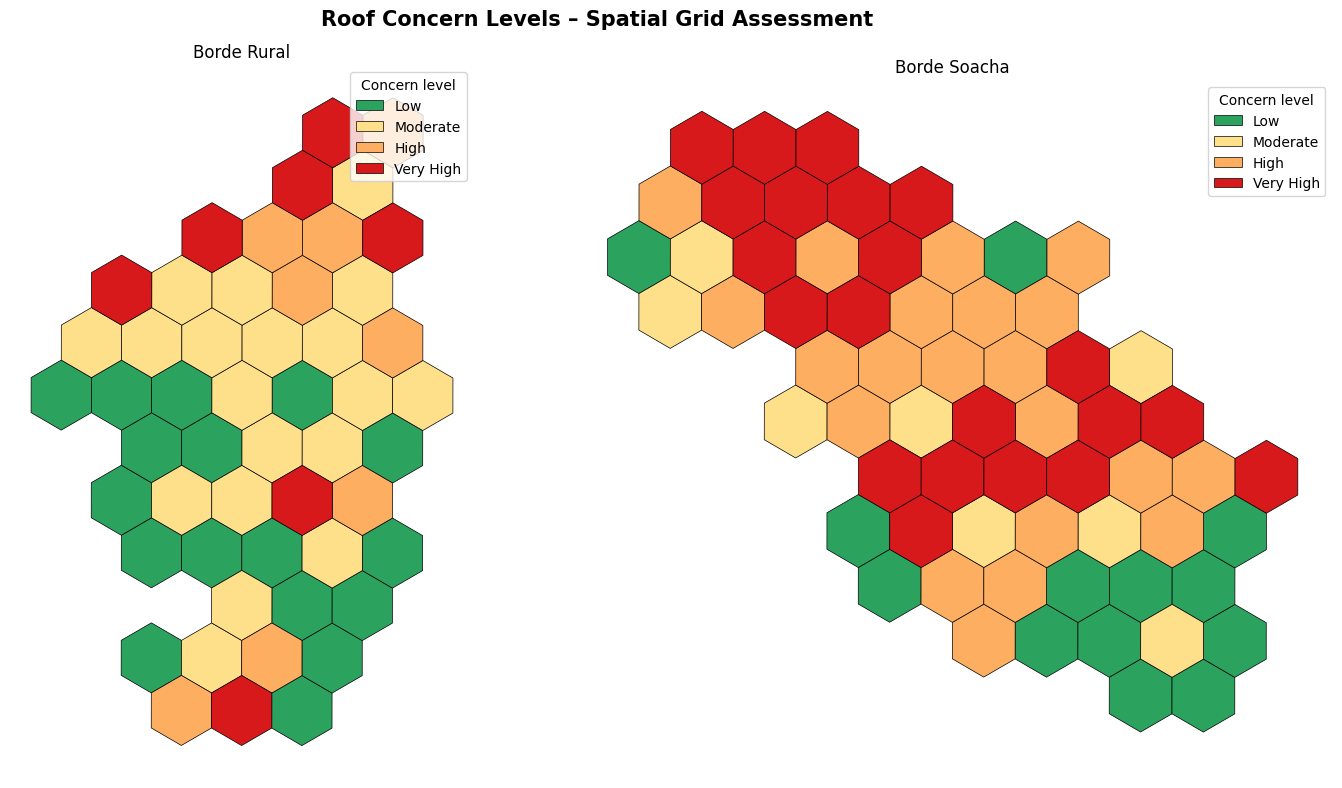


Saved:
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/concern_levels/roof_concern_levels.geojson
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/concern_levels/roof_concern_levels.csv
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/concern_levels/concern_level_summary.csv
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/concern_levels/roof_concern_levels_map.png


In [38]:

import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

INPUT_FILE = (
    f"{ROOT}/vulnerability_mapping/roof_concern_analysis/"
    "roof_concern_grid.geojson"
)

OUTPUT_DIR = f"{ROOT}/vulnerability_mapping/concern_levels"
os.makedirs(OUTPUT_DIR, exist_ok=True)

grid = gpd.read_file(INPUT_FILE)

# Calculate global quartile thresholds across both regions
q1 = grid["roof_concern_proxy"].quantile(0.25)
q2 = grid["roof_concern_proxy"].quantile(0.50)
q3 = grid["roof_concern_proxy"].quantile(0.75)

print("Concern-level thresholds:")
print(f"Low:       <= {q1:.2f}")
print(f"Moderate:  > {q1:.2f} and <= {q2:.2f}")
print(f"High:      > {q2:.2f} and <= {q3:.2f}")
print(f"Very High: > {q3:.2f}")

# Assign categories
conditions = [
    grid["roof_concern_proxy"] <= q1,
    grid["roof_concern_proxy"] <= q2,
    grid["roof_concern_proxy"] <= q3
]

choices = ["Low", "Moderate", "High"]

grid["concern_level"] = np.select(
    conditions,
    choices,
    default="Very High"
)

level_order = ["Low", "Moderate", "High", "Very High"]

grid["concern_level"] = pd.Categorical(
    grid["concern_level"],
    categories=level_order,
    ordered=True
)

# Summary by concern level
summary = (
    grid.groupby("concern_level", observed=False)
    .agg(
        occupied_cells=("grid_id", "count"),
        total_buildings=("building_count", "sum"),
        average_proxy=("roof_concern_proxy", "mean")
    )
    .round(2)
)

print("\n========== OVERALL CONCERN SUMMARY ==========")
display(summary)

# Regional breakdown
regional_summary = pd.crosstab(
    grid["region"],
    grid["concern_level"],
    dropna=False
)

print("\n========== REGIONAL CELL DISTRIBUTION ==========")
display(regional_summary)

# Save outputs
geojson_path = f"{OUTPUT_DIR}/roof_concern_levels.geojson"
csv_path = f"{OUTPUT_DIR}/roof_concern_levels.csv"
summary_path = f"{OUTPUT_DIR}/concern_level_summary.csv"

grid.to_file(geojson_path, driver="GeoJSON")
grid.drop(columns="geometry").to_csv(csv_path, index=False)
summary.to_csv(summary_path)

# Plot concern-level map
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

colors = {
    "Low": "#2ca25f",
    "Moderate": "#fee08b",
    "High": "#fdae61",
    "Very High": "#d7191c"
}

for ax, region in zip(
    axes, ["borde_rural", "borde_soacha"]
):
    subset = grid[grid["region"] == region]

    subset.plot(
        column="concern_level",
        categorical=True,
        cmap=plt.matplotlib.colors.ListedColormap(
            [colors[level] for level in level_order]
        ),
        linewidth=0.5,
        edgecolor="black",
        legend=True,
        legend_kwds={"title": "Concern level"},
        ax=ax
    )

    ax.set_title(region.replace("_", " ").title())
    ax.set_axis_off()

plt.suptitle(
    "Roof Concern Levels – Spatial Grid Assessment",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

map_path = f"{OUTPUT_DIR}/roof_concern_levels_map.png"
plt.savefig(map_path, dpi=250, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(geojson_path)
print(csv_path)
print(summary_path)
print(map_path)


In [39]:

import pandas as pd
import geopandas as gpd

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

INPUT_FILE = (
    f"{ROOT}/vulnerability_mapping/concern_levels/"
    "roof_concern_levels.geojson"
)

grid = gpd.read_file(INPUT_FILE)

# 1. Building support statistics
print("========== BUILDINGS PER GRID CELL ==========")

print(
    grid["building_count"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

# 2. Building distribution by region AND concern level
print("\n========== REGIONAL BUILDING DISTRIBUTION ==========")

regional_buildings = pd.pivot_table(
    grid,
    index="region",
    columns="concern_level",
    values="building_count",
    aggfunc="sum",
    fill_value=0,
    observed=False
)

display(regional_buildings)

# 3. Building counts within each concern category
print("\n========== CELL SUPPORT BY CONCERN LEVEL ==========")

support = (
    grid.groupby("concern_level", observed=False)
    .agg(
        cells=("grid_id", "count"),
        min_buildings=("building_count", "min"),
        median_buildings=("building_count", "median"),
        max_buildings=("building_count", "max"),
        total_buildings=("building_count", "sum")
    )
)

display(support)

# 4. Inspect High and Very High cells
print("\n========== HIGH-CONCERN GRID CELLS ==========")

high_cells = grid[
    grid["concern_level"].isin(["High", "Very High"])
].copy()

high_cells = high_cells.sort_values(
    "roof_concern_proxy", ascending=False
)

display(
    high_cells[
        [
            "grid_id",
            "region",
            "building_count",
            "irregular_metal_pct",
            "incomplete_pct",
            "roof_concern_proxy",
            "concern_level"
        ]
    ].head(15)
)

# 5. Flag cells with fewer than 10 buildings for review.
# This is a preliminary reporting threshold, not a statistical rule.
grid["low_sample_support"] = grid["building_count"] < 10

print("\nCells with fewer than 10 buildings:",
      int(grid["low_sample_support"].sum()))

print("\nBuildings in those cells:",
      int(grid.loc[
          grid["low_sample_support"], "building_count"
      ].sum()))


========== BUILDINGS PER GRID CELL ==========
count    114.00
mean      45.41
std       27.32
min        1.00
10%        6.00
25%       19.25
50%       48.50
75%       68.00
90%       78.70
max      104.00
Name: building_count, dtype: float64

========== REGIONAL BUILDING DISTRIBUTION ==========


concern_level,High,Low,Moderate,Very High
region,,,,
borde_rural,399,481,1047,233
borde_soacha,1179,483,309,1046



========== CELL SUPPORT BY CONCERN LEVEL ==========


,cells,min_buildings,median_buildings,max_buildings,total_buildings
concern_level,,,,,
High,29,7,62.0,84,1578
Low,30,1,29.5,75,964
Moderate,27,2,53.0,91,1356
Very High,28,2,47.0,104,1279



========== HIGH-CONCERN GRID CELLS ==========


,grid_id,region,building_count,irregular_metal_pct,incomplete_pct,roof_concern_proxy,concern_level
111,borde_soacha_r11_c1,borde_soacha,2,100.000000,0.000000,100.000000,Very High
49,borde_rural_r12_c5,borde_rural,10,80.000000,10.000000,90.000000,Very High
109,borde_soacha_r10_c4,borde_soacha,60,65.000000,18.333333,83.333333,Very High
43,borde_rural_r10_c3,borde_rural,19,63.157895,15.789474,78.947368,Very High
112,borde_soacha_r11_c2,borde_soacha,18,77.777778,0.000000,77.777778,Very High
89,borde_soacha_r7_c7,borde_soacha,48,64.583333,12.500000,77.083333,Very High
81,borde_soacha_r6_c6,borde_soacha,69,56.521739,17.391304,73.913043,Very High
113,borde_soacha_r11_c3,borde_soacha,11,63.636364,9.090909,72.727273,Very High
77,borde_soacha_r5_c10,borde_soacha,35,65.714286,5.714286,71.428571,Very High
71,borde_soacha_r5_c4,borde_soacha,65,60.000000,10.769231,70.769231,Very High



Cells with fewer than 10 buildings: 17

Buildings in those cells: 75


In [40]:

import os
import pandas as pd
import geopandas as gpd

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

INPUT_FILE = (
    f"{ROOT}/vulnerability_mapping/concern_levels/"
    "roof_concern_levels.geojson"
)

OUTPUT_DIR = (
    f"{ROOT}/vulnerability_mapping/inspection_priority"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

grid = gpd.read_file(INPUT_FILE)

# Keep High and Very High cells
priority = grid[
    grid["concern_level"].isin(["High", "Very High"])
].copy()

# Flag cells with limited building support
priority["sample_support"] = priority[
    "building_count"
].apply(
    lambda n: "Low support (<10 buildings)"
    if n < 10 else "Better support (>=10 buildings)"
)

# Rank by continuous proxy score, then building count
priority = priority.sort_values(
    ["roof_concern_proxy", "building_count"],
    ascending=[False, False]
).reset_index(drop=True)

priority.insert(
    0, "screening_rank",
    range(1, len(priority) + 1)
)

columns = [
    "screening_rank",
    "grid_id",
    "region",
    "concern_level",
    "building_count",
    "irregular_metal",
    "irregular_metal_pct",
    "incomplete",
    "incomplete_pct",
    "roof_concern_proxy",
    "sample_support"
]

priority_table = priority[columns]

print("HIGH-CONCERN INSPECTION SHORTLIST")
display(priority_table)

print("\nSUPPORT SUMMARY")
display(
    priority.groupby(
        ["concern_level", "sample_support"],
        observed=False
    ).agg(
        cells=("grid_id", "count"),
        buildings=("building_count", "sum")
    )
)

# Export shortlist
csv_path = f"{OUTPUT_DIR}/inspection_priority_shortlist.csv"
geojson_path = f"{OUTPUT_DIR}/inspection_priority_shortlist.geojson"

priority_table.to_csv(csv_path, index=False)
priority.to_file(geojson_path, driver="GeoJSON")

print("\nSaved:")
print(csv_path)
print(geojson_path)


HIGH-CONCERN INSPECTION SHORTLIST


,screening_rank,grid_id,region,concern_level,building_count,irregular_metal,irregular_metal_pct,incomplete,incomplete_pct,roof_concern_proxy,sample_support
0,1,borde_soacha_r11_c1,borde_soacha,Very High,2,2,100.000000,0,0.000000,100.000000,Low support (<10 buildings)
1,2,borde_rural_r12_c5,borde_rural,Very High,10,8,80.000000,1,10.000000,90.000000,Better support (>=10 buildings)
2,3,borde_soacha_r10_c4,borde_soacha,Very High,60,39,65.000000,11,18.333333,83.333333,Better support (>=10 buildings)
3,4,borde_rural_r10_c3,borde_rural,Very High,19,12,63.157895,3,15.789474,78.947368,Better support (>=10 buildings)
4,5,borde_soacha_r11_c2,borde_soacha,Very High,18,14,77.777778,0,0.000000,77.777778,Better support (>=10 buildings)
5,6,borde_soacha_r7_c7,borde_soacha,Very High,48,31,64.583333,6,12.500000,77.083333,Better support (>=10 buildings)
6,7,borde_soacha_r6_c6,borde_soacha,Very High,69,39,56.521739,12,17.391304,73.913043,Better support (>=10 buildings)
7,8,borde_soacha_r11_c3,borde_soacha,Very High,11,7,63.636364,1,9.090909,72.727273,Better support (>=10 buildings)
8,9,borde_soacha_r5_c10,borde_soacha,Very High,35,23,65.714286,2,5.714286,71.428571,Better support (>=10 buildings)
9,10,borde_soacha_r5_c4,borde_soacha,Very High,65,39,60.000000,7,10.769231,70.769231,Better support (>=10 buildings)



SUPPORT SUMMARY


cells  buildings
concern_level sample_support                                   
High          Better support (>=10 buildings)     28       1571
              Low support (<10 buildings)          1          7
Very High     Better support (>=10 buildings)     25       1268
              Low support (<10 buildings)          3         11


Saved:
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/inspection_priority/inspection_priority_shortlist.csv
/content/drive/MyDrive/RoofMaterialProject/vulnerability_mapping/inspection_priority/inspection_priority_shortlist.geojson


In [41]:
"""interactive dashboard"""

'interactive dashboard'

In [42]:
!pip install -q streamlit geopandas folium streamlit-folium plotly

In [43]:

%%writefile /content/drive/MyDrive/RoofMaterialProject/app.py

import os
import streamlit as st
import pandas as pd
import geopandas as gpd
import folium
import plotly.express as px

from streamlit_folium import st_folium

# --------------------------------------------------
# 1. PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="RoofInsight | Spatial Inspection",
    page_icon="🏘️",
    layout="wide"
)

ROOT = "/content/drive/MyDrive/RoofMaterialProject"

GRID_FILE = (
    f"{ROOT}/vulnerability_mapping/concern_levels/"
    "roof_concern_levels.geojson"
)

BUILDING_FILE = (
    f"{ROOT}/vulnerability_mapping/spatial_join/"
    "test_buildings_with_predictions.geojson"
)

CLASSES = [
    "healthy_metal",
    "irregular_metal",
    "incomplete",
    "concrete_cement"
]

CLASS_COLORS = {
    "healthy_metal": "#16A36A",
    "irregular_metal": "#E58B32",
    "incomplete": "#D84B42",
    "concrete_cement": "#64748B"
}

LEVEL_COLORS = {
    "Low": "#2CA25F",
    "Moderate": "#FEE08B",
    "High": "#FDAE61",
    "Very High": "#D7191C"
}

# --------------------------------------------------
# 2. LOAD DATA
# --------------------------------------------------

@st.cache_data
def load_data(grid_file, building_file):

    grid = gpd.read_file(grid_file)
    buildings = gpd.read_file(building_file)

    # Handle possible building ID naming difference
    if "building_id" not in buildings.columns:
        if "id" in buildings.columns:
            buildings = buildings.rename(
                columns={"id": "building_id"}
            )
        else:
            raise ValueError(
                "No building_id or id column found."
            )

    required_grid = [
        "grid_id",
        "region",
        "building_count",
        "roof_concern_proxy",
        "concern_level",
        "healthy_metal_pct",
        "irregular_metal_pct",
        "incomplete_pct",
        "concrete_cement_pct",
        "geometry"
    ]

    required_buildings = [
        "building_id",
        "region",
        "predicted",
        "geometry"
    ]

    missing_grid = [
        c for c in required_grid
        if c not in grid.columns
    ]

    missing_buildings = [
        c for c in required_buildings
        if c not in buildings.columns
    ]

    if missing_grid:
        raise ValueError(
            f"Missing grid columns: {missing_grid}"
        )

    if missing_buildings:
        raise ValueError(
            f"Missing building columns: {missing_buildings}"
        )

    if grid.crs is None or buildings.crs is None:
        raise ValueError("Missing CRS information.")

    grid["concern_level"] = (
        grid["concern_level"].astype(str)
    )

    # Use the same geographic CRS for display
    grid = grid.to_crs("EPSG:4326")
    buildings = buildings.to_crs("EPSG:4326")

    # Create representative points for building assignment
    buildings = buildings.reset_index(drop=True)

    points = buildings[
        ["building_id", "geometry"]
    ].copy()

    points["geometry"] = (
        points.geometry.representative_point()
    )

    points["_row_id"] = range(len(points))

    # Spatially associate each building with one hexagon
    joined = gpd.sjoin(
        points,
        grid[["grid_id", "geometry"]],
        how="left",
        predicate="within"
    )

    # Validate assignment
    if joined["grid_id"].isna().any():
        missing_count = joined["grid_id"].isna().sum()
        raise ValueError(
            f"{missing_count} buildings could not be "
            "assigned to a grid cell."
        )

    if joined["building_id"].duplicated().any():
        raise ValueError(
            "Some buildings were assigned to multiple cells."
        )

    if len(joined) != len(buildings):
        raise ValueError(
            "Building-to-grid assignment count mismatch."
        )

    # Attach grid IDs to original building polygons
    assignment = (
        joined[["_row_id", "grid_id"]]
        .set_index("_row_id")["grid_id"]
    )

    buildings["grid_id"] = (
        buildings.index.map(assignment)
    )

    return grid, buildings


# --------------------------------------------------
# 3. CHECK INPUT FILES
# --------------------------------------------------

st.title("🏘️ RoofInsight")
st.caption(
    "AI-Based Roof Material Classification "
    "and Spatial Inspection Dashboard"
)

if not os.path.exists(GRID_FILE):
    st.error(f"Grid file not found: {GRID_FILE}")
    st.stop()

if not os.path.exists(BUILDING_FILE):
    st.error(f"Building file not found: {BUILDING_FILE}")
    st.stop()

try:
    grid, buildings = load_data(
        GRID_FILE,
        BUILDING_FILE
    )
except Exception as e:
    st.error(f"Data loading error: {e}")
    st.stop()

# --------------------------------------------------
# 4. SIDEBAR FILTERS
# --------------------------------------------------

st.sidebar.title("Inspection Filters")

regions = sorted(grid["region"].unique().tolist())

selected_region = st.sidebar.selectbox(
    "Select study region",
    regions
)

level_order = [
    "Low",
    "Moderate",
    "High",
    "Very High"
]

selected_levels = st.sidebar.multiselect(
    "Filter concern levels",
    level_order,
    default=level_order
)

selected_materials = st.sidebar.multiselect(
    "Filter by roof material",
    CLASSES,
    default=CLASSES,
    format_func=lambda x: x.replace("_", " ").title()
)

region_grid = grid[
    (grid["region"] == selected_region)
    & (grid["concern_level"].isin(selected_levels))
].copy()

# Apply material filter to map cells:
# show cells containing at least one selected material.
if selected_materials:
    region_grid = region_grid[
        region_grid[selected_materials].sum(axis=1) > 0
    ]
else:
    region_grid = region_grid.iloc[0:0]

region_buildings = buildings[
    buildings["region"] == selected_region
].copy()

# --------------------------------------------------
# 5. REGIONAL OVERVIEW
# --------------------------------------------------

st.header(
    selected_region.replace("_", " ").title()
)

total_buildings = len(region_buildings)
occupied_cells = len(
    grid[grid["region"] == selected_region]
)

high_very_high = grid[
    (grid["region"] == selected_region)
    & (grid["concern_level"].isin(["High", "Very High"]))
]

high_buildings = int(
    high_very_high["building_count"].sum()
)

high_pct = (
    high_buildings / total_buildings * 100
    if total_buildings else 0
)

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Buildings analyzed",
    f"{total_buildings:,}"
)

c2.metric(
    "Occupied grid cells",
    f"{occupied_cells:,}"
)

c3.metric(
    "Buildings in High / Very High cells",
    f"{high_buildings:,}"
)

c4.metric(
    "High / Very High building share",
    f"{high_pct:.2f}%"
)

st.divider()

# --------------------------------------------------
# 6. REGIONAL ROOF MATERIAL COMPOSITION
# --------------------------------------------------

st.subheader("Regional Roof Material Composition")

regional_counts = (
    grid[grid["region"] == selected_region][CLASSES]
    .sum()
)

regional_total = regional_counts.sum()

regional_material_data = pd.DataFrame({
    "Roof material": [
        c.replace("_", " ").title()
        for c in CLASSES
    ],
    "Buildings": [
        int(regional_counts[c])
        for c in CLASSES
    ],
    "Percentage": [
        regional_counts[c] / regional_total * 100
        if regional_total else 0
        for c in CLASSES
    ]
})

left, right = st.columns([1.2, 1])

with left:
    fig = px.bar(
        regional_material_data,
        x="Roof material",
        y="Percentage",
        color="Roof material",
        text=regional_material_data[
            "Percentage"
        ].map(lambda x: f"{x:.2f}%"),
        title="Roof Material Distribution",
        color_discrete_sequence=[
            CLASS_COLORS[c] for c in CLASSES
        ]
    )

    fig.update_layout(
        showlegend=False,
        yaxis_title="Buildings (%)",
        xaxis_title=""
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

with right:
    st.dataframe(
        regional_material_data,
        hide_index=True,
        use_container_width=True
    )

st.divider()

# --------------------------------------------------
# 7. INTERACTIVE GRID MAP
# --------------------------------------------------

st.subheader("Interactive Spatial Concern Map")

st.caption(
    "Click a hexagon to view its popup. "
    "Use the grid selector below to load its "
    "individual building polygons and full details."
)

if region_grid.empty:
    st.warning(
        "No grid cells match the selected filters."
    )
    st.stop()

minx, miny, maxx, maxy = (
    region_grid.total_bounds
)

center = [
    (miny + maxy) / 2,
    (minx + maxx) / 2
]

m = folium.Map(
    location=center,
    zoom_start=14,
    tiles="CartoDB positron"
)

def grid_style(feature):
    level = feature["properties"]["concern_level"]

    return {
        "fillColor": LEVEL_COLORS.get(
            level, "#808080"
        ),
        "color": "#333333",
        "weight": 1.2,
        "fillOpacity": 0.72
    }

folium.GeoJson(
    region_grid,
    name="Concern grid cells",
    style_function=grid_style,
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "grid_id",
            "concern_level",
            "building_count",
            "roof_concern_proxy"
        ],
        aliases=[
            "Grid ID:",
            "Concern level:",
            "Buildings:",
            "Concern proxy:"
        ],
        localize=True
    ),
    popup=folium.GeoJsonPopup(
        fields=[
            "grid_id",
            "concern_level",
            "building_count",
            "roof_concern_proxy",
            "healthy_metal_pct",
            "irregular_metal_pct",
            "incomplete_pct",
            "concrete_cement_pct"
        ],
        aliases=[
            "Grid ID:",
            "Concern level:",
            "Building count:",
            "Concern proxy:",
            "Healthy metal (%):",
            "Irregular metal (%):",
            "Incomplete (%):",
            "Concrete/cement (%):"
        ],
        localize=True
    )
).add_to(m)

# --------------------------------------------------
# 8. GRID CELL SELECTION
# --------------------------------------------------

grid_options = region_grid.sort_values(
    "roof_concern_proxy",
    ascending=False
)["grid_id"].tolist()

default_grid = grid_options[0]

if (
    "selected_grid" not in st.session_state
    or st.session_state["selected_grid"] not in grid_options
):
    st.session_state["selected_grid"] = default_grid

selected_grid = st.selectbox(
    "Select a grid cell for detailed inspection",
    grid_options,
    key="selected_grid"
)

selected_row = grid[
    grid["grid_id"] == selected_grid
].iloc[0]

selected_buildings = region_buildings[
    region_buildings["grid_id"] == selected_grid
].copy()

# Highlight selected hexagon
selected_polygon = grid[
    grid["grid_id"] == selected_grid
]

folium.GeoJson(
    selected_polygon,
    name="Selected grid cell",
    style_function=lambda feature: {
        "fillColor": "#00BFFF",
        "color": "#003366",
        "weight": 4,
        "fillOpacity": 0.12
    }
).add_to(m)

# --------------------------------------------------
# 9. INDIVIDUAL BUILDING POLYGONS
# --------------------------------------------------

if not selected_buildings.empty:

    building_layer = folium.FeatureGroup(
        name="Individual buildings",
        show=True
    )

    for _, building in selected_buildings.iterrows():

        roof_class = building["predicted"]

        color = CLASS_COLORS.get(
            roof_class, "#808080"
        )

        building_gdf = gpd.GeoDataFrame(
            [building],
            geometry="geometry",
            crs=selected_buildings.crs
        )

        folium.GeoJson(
            building_gdf,
            style_function=lambda feature, c=color: {
                "fillColor": c,
                "color": "#222222",
                "weight": 1,
                "fillOpacity": 0.8
            },
            tooltip=folium.Tooltip(
                f"Building ID: {building['building_id']}<br>"
                f"Roof material: "
                f"{str(roof_class).replace('_', ' ').title()}"
            )
        ).add_to(building_layer)

    building_layer.add_to(m)

folium.LayerControl(
    collapsed=False
).add_to(m)

m.fit_bounds(
    [[miny, minx], [maxy, maxx]]
)

st_folium(
    m,
    use_container_width=True,
    height=620,
    returned_objects=[]
)

st.divider()

# --------------------------------------------------
# 10. SELECTED GRID CELL DETAILS
# --------------------------------------------------

st.subheader("Selected Grid Cell Inspection")

d1, d2, d3 = st.columns(3)

d1.metric(
    "Building count",
    int(selected_row["building_count"])
)

d2.metric(
    "Roof concern proxy",
    f"{selected_row['roof_concern_proxy']:.2f}/100"
)

d3.metric(
    "Concern level",
    selected_row["concern_level"]
)

if int(selected_row["building_count"]) < 10:
    st.warning(
        "Low sample support: this cell contains fewer "
        "than 10 buildings. Interpret its percentages "
        "with caution."
    )
else:
    st.info(
        "This cell has at least 10 buildings. "
        "This is a preliminary sample-support flag, "
        "not a statistical reliability guarantee."
    )

# --------------------------------------------------
# 11. ALL FOUR ROOF MATERIALS IN SELECTED CELL
# --------------------------------------------------

st.markdown("### Roof Material Breakdown")

material_rows = []

for cls in CLASSES:

    count = int(selected_row[cls])

    percentage = float(
        selected_row[f"{cls}_pct"]
    )

    material_rows.append({
        "Roof material": cls.replace(
            "_", " "
        ).title(),
        "Buildings": count,
        "Percentage": round(percentage, 2)
    })

material_df = pd.DataFrame(material_rows)

left, right = st.columns([1, 1])

with left:
    fig = px.bar(
        material_df,
        x="Roof material",
        y="Percentage",
        color="Roof material",
        text=material_df[
            "Percentage"
        ].map(lambda x: f"{x:.2f}%"),
        color_discrete_sequence=[
            CLASS_COLORS[c] for c in CLASSES
        ],
        title="Selected Cell: Roof Composition"
    )

    fig.update_layout(
        showlegend=False,
        yaxis_title="Buildings (%)",
        xaxis_title=""
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

with right:
    st.dataframe(
        material_df,
        hide_index=True,
        use_container_width=True
    )

# --------------------------------------------------
# 12. BUILDING-LEVEL INSPECTION TABLE
# --------------------------------------------------

st.markdown("### Individual Buildings in Selected Cell")

if selected_buildings.empty:

    st.warning(
        "No building polygons were assigned to this cell."
    )

else:

    building_table = selected_buildings[
        ["building_id", "predicted"]
    ].copy()

    building_table["predicted"] = (
        building_table["predicted"]
        .str.replace("_", " ")
        .str.title()
    )

    st.write(
        f"Showing {len(building_table)} buildings "
        f"inside {selected_grid}."
    )

    st.dataframe(
        building_table,
        hide_index=True,
        use_container_width=True
    )

    st.download_button(
        "Download selected cell building records",
        data=building_table.to_csv(index=False),
        file_name=f"{selected_grid}_buildings.csv",
        mime="text/csv"
    )

st.divider()

# --------------------------------------------------
# 13. REGIONAL CONCERN DISTRIBUTION
# --------------------------------------------------

st.subheader("Concern-Level Distribution")

level_counts = (
    grid[grid["region"] == selected_region]
    .groupby("concern_level")
    .agg(
        occupied_cells=("grid_id", "count"),
        buildings=("building_count", "sum")
    )
    .reindex(level_order, fill_value=0)
    .reset_index()
)

fig = px.bar(
    level_counts,
    x="concern_level",
    y="buildings",
    color="concern_level",
    text="buildings",
    color_discrete_map=LEVEL_COLORS,
    title="Buildings by Concern Level"
)

fig.update_layout(
    showlegend=False,
    xaxis_title="Concern level",
    yaxis_title="Number of buildings"
)

st.plotly_chart(
    fig,
    use_container_width=True
)

st.dataframe(
    level_counts,
    hide_index=True,
    use_container_width=True
)

# --------------------------------------------------
# 14. DOWNLOAD FILTERED GRID DATA
# --------------------------------------------------

st.subheader("Export Inspection Data")

export_grid = region_grid.drop(
    columns="geometry"
).copy()

st.download_button(
    "Download filtered grid records",
    data=export_grid.to_csv(index=False),
    file_name=f"{selected_region}_grid_inspection.csv",
    mime="text/csv"
)

priority_export = region_grid[
    region_grid["concern_level"].isin(
        ["High", "Very High"]
    )
].drop(columns="geometry")

st.download_button(
    "Download High / Very High cells",
    data=priority_export.to_csv(index=False),
    file_name=f"{selected_region}_priority_cells.csv",
    mime="text/csv"
)

# --------------------------------------------------
# 15. FOOTER
# --------------------------------------------------

st.divider()

st.caption(
    "RoofInsight | Roof Material Classification "
    "and Spatial Concern Screening"
)

st.caption(
    "Concern proxy = irregular metal percentage "
    "+ incomplete roof percentage. "
    "Concern levels are relative, data-derived "
    "screening categories, not validated engineering "
    "or disaster-risk ratings. All roof classes are "
    "model predictions and should be field-verified."
)


Writing /content/drive/MyDrive/RoofMaterialProject/app.py


In [44]:
!streamlit run /content/drive/MyDrive/RoofMaterialProject/app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    > /content/streamlit.log 2>&1 &

In [46]:
!npx localtunnel --port 8501

⠙⠹⠸⠼Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) ^C


In [47]:
!cat /content/streamlit.log



2026-11-11 13:25:44.299 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.16.170.160:8501

  Stopping...


In [48]:
!curl -I http://127.0.0.1:8501

curl: (7) Failed to connect to 127.0.0.1 port 8501 after 0 ms: Couldn't connect to server
